In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

# from solvers import MMGKS
from msolver import MMGKS

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

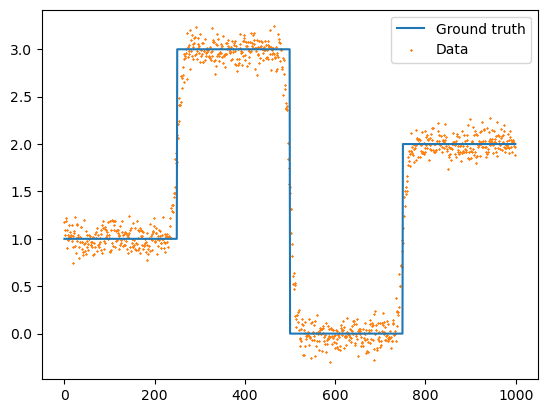

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

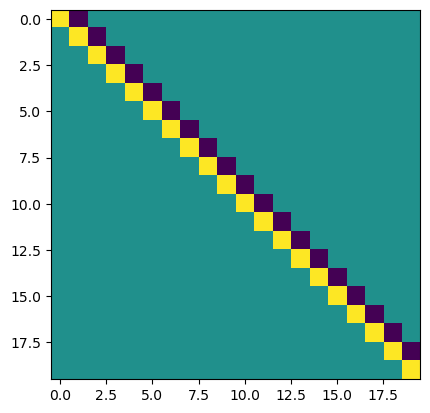

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Use solver

In [25]:
mmgks_solver = MMGKS(A, L, noisy_signal, noise_var=noise_var)
#data = mmgks_solver.solve(n_iter=150, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="dp3", tol=1e-5)
#data = mmgks_solver.solve(n_iter=150, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="gcv")
#data = mmgks_solver.solve(n_iter=150, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="dp", explicitProj=True, eta=1.05)
data = mmgks_solver.solve(n_iter=200, x_true=ground_truth, regparam="dp", explicitProj=True, eta=1.05, weight_params={"epsilon":1e-3, "q":1.0})

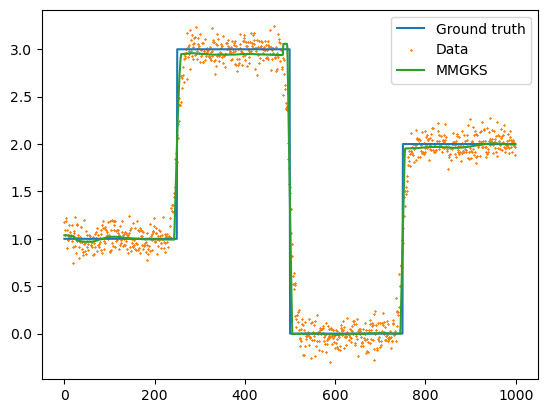

In [26]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, data["x"], label="MMGKS", color="C2")
plt.legend()
plt.show()
plt.show()

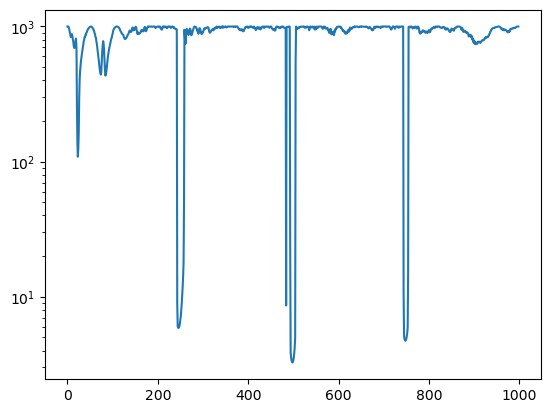

In [36]:
plt.semilogy(data["w"])
plt.show()

In [27]:
data["rre_history"][-1]

0.06789501895273588

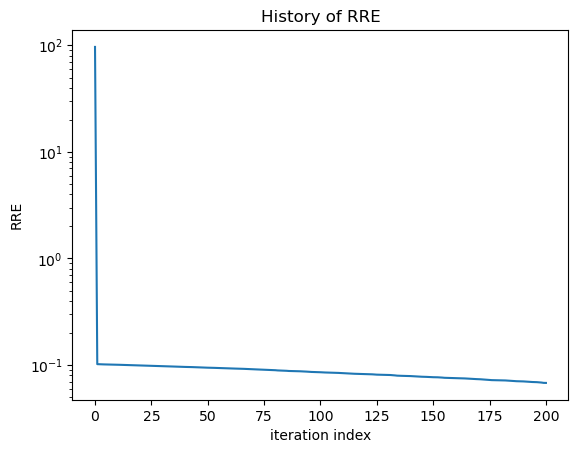

In [28]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

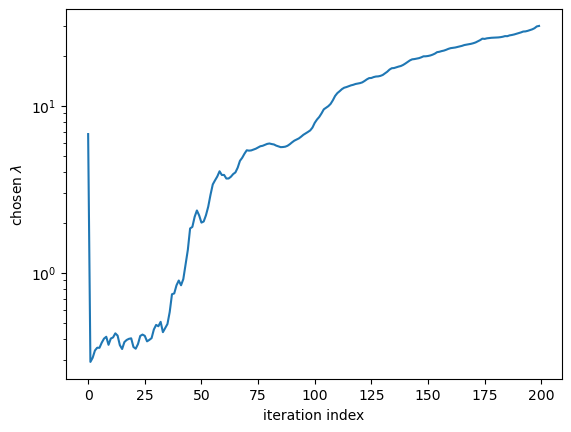

In [29]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

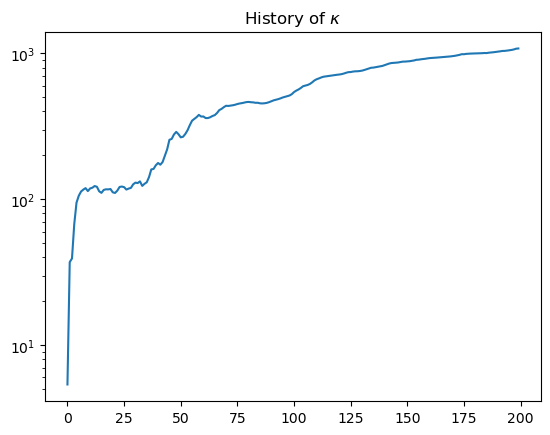

In [30]:
plt.plot(data["cond_ests"])
plt.yscale("log")
plt.title("History of $\\kappa$")
plt.show()

In [12]:
from msolver import VanillaGKS

In [13]:
vgks_solver = VanillaGKS(A, L, noisy_signal, noise_var=noise_var)
#data = mmgks_solver.solve(n_iter=150, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="dp3", tol=1e-5)
#data = mmgks_solver.solve(n_iter=150, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="gcv")
#data = mmgks_solver.solve(n_iter=150, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="dp", explicitProj=True, eta=1.05)
vdata = vgks_solver.solve(n_iter=200, x_true=ground_truth, regparam="dp", explicitProj=True, eta=1.05, weight_params={})

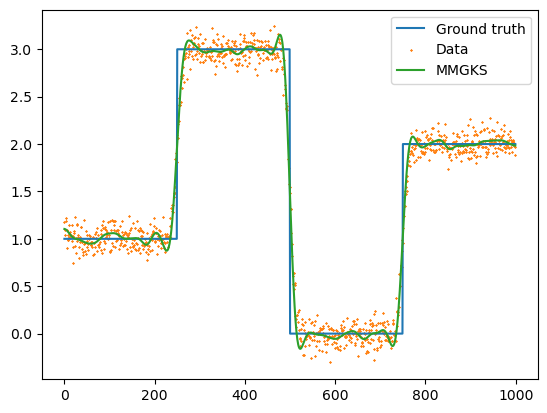

In [15]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, vdata["x"], label="MMGKS", color="C2")
plt.legend()
plt.show()
plt.show()

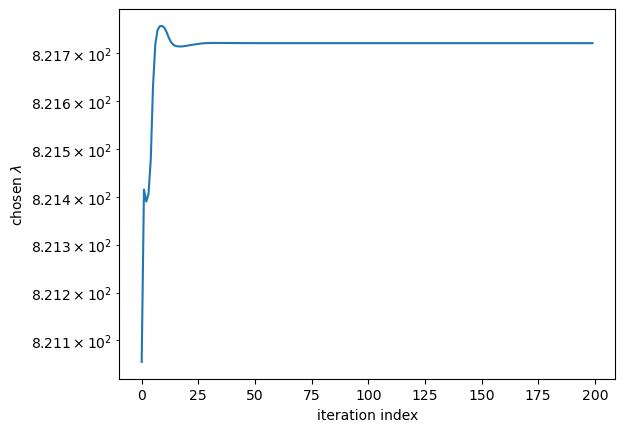

In [17]:
plt.plot(vdata["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

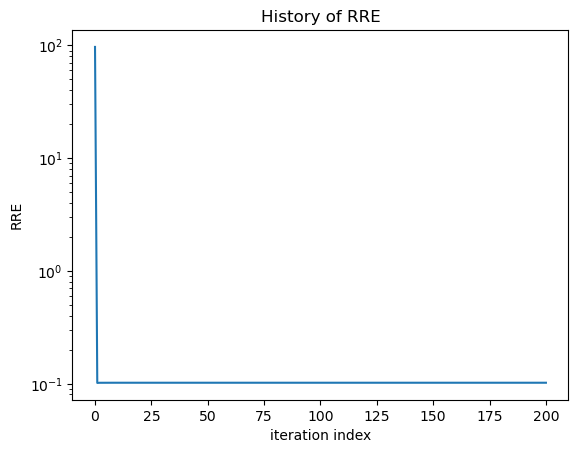

In [18]:
plt.plot(vdata["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()